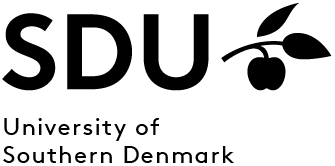
<br><br><br>
<p style="color: #789D4A;font-family: courier;font-size: 160%;text-align:center;">Optimization and Image Processing (E26)</p> 

<p style="color: #789D4A;font-family: courier;font-size: 120%;text-align:center;">Dr Till Leissner, Associate Professor</p> 
<p style="color: #789D4A;font-family: courier;font-size: 120%;text-align:center;">Mads Clausen Institute, University of Southern Denmark</p> 

# Final project: Thermographic defect detection using image processing and optimisation

Non-destructive testing (NDT) aims to detect defects in engineering components without damaging the component. One approach is **infrared thermography**: a surface is heated and an infrared camera records the resulting temperature field. A subsurface defect changes heat flow and can therefore create a visible thermal signature.

In this project you will analyse real thermographic data from a published GFRP (glass-fibre-reinforced polymer) reference dataset:

> J. Lecompagnon, A. Sarhadi, R. Albuquerque, and M. A. Eder,  
> *Thermographic Reference Dataset: Experimentally simulated Gaussian-shaped internal defects in GFRP*, Zenodo, 2025.  
> DOI: **10.5281/zenodo.17378682**

You can find some datasets in the `data`subfolder. Choose at least one.

The project combines two main parts of the course:

1. **Image processing** for enhancement, denoising, segmentation, and geometric measurements.
2. **Optimisation** for refining a simple model of the thermal signature.

The central project question is:

> **Can classical image processing locate and characterize a thermal defect, and how much can optimisation improve the estimate?**

You will compare three optimisation strategies:

- gradient-based optimisation,
- Nelder–Mead,
- particle swarm optimisation (PSO).

You should compare **accuracy, robustness, computational effort, and interpretability**.

## Project structure

The project has four connected parts:

### Part A — Warm-up with a synthetic thermal image
Build and test the image-processing workflow on a problem with known ground truth.

### Part B — Image processing of a real thermographic dataset
Inspect, enhance, denoise, segment, and measure the experimental field.

### Part C — Optimisation
Use the image-processing result as the starting point for a simple Gaussian model fit.

### Part D — Comparison and engineering interpretation
Compare image-processing-only results with three optimisation methods and report the final result in physical units.


## What to submit

Work in groups of **up to four students**.

Submit **one completed Jupyter notebook per group**. The notebook should contain both your code and your written explanations, figures, results, and discussion.

Your submission should be readable as a short technical report. Another reader should be able to understand what you did without having to inspect the code alone.

Your notebook should include:

- the names of all group members,
- all required image-processing and optimisation tasks,
- relevant plots and intermediate results,
- the final parameter estimates and comparisons between methods,
- short explanations of the choices you made,
- discussion of the behaviour of the different optimisation methods,
- interpretation of the results in the engineering context,
- answers to all discussion and reflection questions in the notebook.

Please keep the notebook organised and remove unnecessary test code, debugging output, and unused cells before submission.

You are encouraged to work collaboratively and discuss approaches within your group. However, your submitted notebook should reflect your group's own analysis and understanding.

**Submit the completed `.ipynb` file via itslearning.**

## Use of AI tools

If you use AI tools such as ChatGPT, Copilot, Gemini, Claude, or similar systems while working on the project, you must **state this clearly in your submitted notebook**.

At the end of the notebook, include a short **AI usage statement** describing:

- **which AI tool(s)** you used,
- **where** in the project you used them,
- **what you used them for**, for example:
  - understanding a concept,
  - debugging code,
  - suggesting an implementation,
  - improving plots,
  - improving language,
  - discussing or interpreting results,
- **approximately how much** of the submitted work was supported by AI,
- and **how you verified** that the AI-generated suggestions, code, or explanations were correct.

You remain responsible for all submitted code, results, explanations, and conclusions. You should therefore be able to **explain and justify any part of your notebook**, including parts developed with AI assistance.

A brief statement is sufficient, for example:

> **AI usage:** We used ChatGPT mainly to help debug the PSO implementation and to improve the wording of our discussion. Approximately 10–20% of the coding process involved AI assistance. All suggested code was tested and compared with the course material, and the final interpretation was written and checked by the group.

If you did not use any AI tools, simply state:

> **AI usage:** No generative AI tools were used for this project.

In [ ]:
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt

from scipy import ndimage
from scipy.optimize import minimize

from skimage import exposure, filters, measure, morphology

# Part A — Warm-up: synthetic thermal defect

The following cell generates a simple temperature field containing:

- a smooth background,
- one Gaussian-shaped thermal feature,
- additive noise.

Because the true parameters are known, you can test whether your image-processing pipeline is reasonable before working with the experimental dataset.

In [ ]:
rng = np.random.default_rng(5)

H, W = 120, 160
y_syn, x_syn = np.mgrid[:H, :W]

true_x0 = 95.0
true_y0 = 62.0
true_sigma = 12.0
true_amplitude = 4.0

synthetic_signal = true_amplitude * np.exp(
    -((x_syn - true_x0) ** 2 + (y_syn - true_y0) ** 2)
    / (2 * true_sigma**2)
)

synthetic_background = 20.0 + 0.002 * x_syn
synthetic_noise = rng.normal(scale=0.18, size=(H, W))

synthetic_image = synthetic_background + synthetic_signal + synthetic_noise

## A1 — Inspect the image and histogram

Display the synthetic image and its histogram.

Briefly discuss:

- whether the defect is easy to identify,
- how much of the histogram belongs to background pixels,
- whether contrast enhancement would help.

In [ ]:
# Display the synthetic image and its histogram.

# YOUR CODE HERE
raise NotImplementedError()

### A1 discussion

## A2 — Contrast enhancement

Compare:

- original image,
- linear contrast stretching,
- histogram equalisation.

Use e.g. the methods available from `skimage.exposure`.

> Which representation is most useful for visualisation/segmentation, and which should be used later for quantitative fitting?

In [ ]:
# Visual comparism

# YOUR CODE HERE
raise NotImplementedError()

### A2 discussion


## A3 — Noise reduction

Compare:

- Gaussian filtering,
- median filtering.

Use a modest filter size.

Discuss which one better preserves the smooth thermal feature.

In [ ]:
# Denoise and display

# YOUR CODE HERE
raise NotImplementedError()

### A3 discussion



## A4 — Detect the synthetic defect

Use a simple classical image-processing pipeline. One suitable approach is:

```text
background correction
    ↓
Gaussian smoothing
    ↓
thresholding
    ↓
morphological cleanup
    ↓
largest connected component
```

From the detected region estimate(using e.g. skimage.measure):

- centroid $(x_c,y_c)$,
- area,
- equivalent radius

$$
r_\mathrm{eq}=\sqrt{\frac{A_\mathrm{region}}{\pi}}.
$$

Compare the estimated centre with the known ground truth.

In [ ]:
# Estimate border background
# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
# Filtering, estimate centre
# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
# Display and compare
# YOUR CODE HERE
raise NotImplementedError()

# Part B — Real thermographic data

The project uses the experimental HDF5 measurement files

├── Meas_data_pattern_001-S11_38.73-S12_5.40-S22_25.07.h5
├── Meas_data_pattern_108-S11_48.53-S12_3.00-S22_18.98.h5
├── Meas_data_pattern_134-S11_45.10-S12_-1.50-S22_19.85.h5
├── Meas_data_pattern_153-S11_41.67-S12_3.60-S22_21.59.h5
├── Meas_data_pattern_174-S11_44.12-S12_9.00-S22_23.62.h5
└── Meas_data_pattern_187-S11_41.18-S12_-12.30-S22_22.46.h5

which can be opened using the `h5py` library. *Choose one of them.* Later you can test your code with a few more.

The most relevant datasets are:

| HDF5 entry | Meaning | Use |
|---|---|---|
| `T_meas` | measured temperature field | **main image for the project** |
| `pixel_size_on_sample_mm` | spatial calibration | convert px → mm |
| `pattern_number` | pattern identifier | metadata |
| `DTU_pattern_data` | source/reference pattern | context only |
| `BAM_pattern_projected_mean` | projected/averaged pattern | context only |
| `S11`, `S12`, `S22` | pattern parameters | metadata |

The core analysis should be performed on `T_meas`.

In [ ]:
# Define data paths

DATA = Path("data")
h5_path = DATA / "Meas_data_pattern_001-S11_38.73-S12_5.40-S22_25.07.h5"

## B1 — Inspect the HDF5 file

Print the top-level datasets, shapes, and data types.

This is good practice whenever you receive an unfamiliar HDF5 file.

In [ ]:
# Open file and show content
# YOUR CODE HERE
raise NotImplementedError()

## B2 — Load the relevant data

Load:

- `T_meas`,
- `pixel_size_on_sample_mm`,
- `pattern_number`,
- `DTU_pattern_data`,
- `BAM_pattern_projected_mean`.

The `S11`, `S12`, and `S22` values can also be loaded as reference metadata.

In [ ]:
# Load the dataset
# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
# Plot relevant data (source, projected, measured)
# YOUR CODE HERE
raise NotImplementedError()

## B3 — Inspect image and histogram

Display the measured field and its histogram.

Comment on:

- background variation,
- contrast,
- noise,
- whether the thermal feature appears symmetric,
- whether any borders or artefacts should be ignored.

In [ ]:
# Diplay and show histogram
# YOUR CODE HERE
raise NotImplementedError()

YOUR ANSWER HERE

## B4 — Background correction, contrast enhancement, and denoising

1. Estimate a constant background from the image border.
2. Subtract it and clip negative values.
3. Create a contrast-stretched and histogram-equalised view.
4. Compare Gaussian and median filtering.
5. Choose one filtered image for segmentation.

Use the **background-corrected non-equalised image** later for quantitative fitting.

In [ ]:
# Estimate background
# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
# Plots
# YOUR CODE HERE
raise NotImplementedError()

### B4 discussion

Explain which representation you chose for segmentation and why the histogram-equalised image should not be used directly for quantitative fitting.


## B5 — Segment the defect and estimate centre/size

Use a simple threshold-based segmentation with morphological cleanup.

You may adapt the thresholding strategy if needed.

Report:

- centroid $(x_c,y_c)$,
- region area,
- equivalent radius,
- equivalent diameter.

Overlay the detected region/centroid on the image.

In [ ]:
# Filtering and centre detection
# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
# Show filtered field, edge magnitude and detected region
# YOUR CODE HERE
raise NotImplementedError()

# Part C — Gaussian model and optimisation

We approximate the thermal feature by a circular Gaussian

$$
G(x,y;\mathbf p)
=
A\exp\left[
-\frac{(x-x_0)^2+(y-y_0)^2}{2\sigma^2}
\right].
$$

The parameter vector is

$$
\mathbf p=(x_0,y_0,\sigma,A).
$$

The parameters are bounded to remain physically meaningful:

- $0\le x_0<W$,
- $0\le y_0<H$,
- $1\le \sigma\le \min(H,W)/3$,
- $0\le A\le 2\max(I)$.

These are simple **box constraints**.

In [ ]:
# Define Gaussian model as function
# YOUR CODE HERE
raise NotImplementedError()

## C1 — Initial guess from image processing

Construct

$$
\mathbf p_0=(x_0,y_0,\sigma_0,A_0)
$$

from the segmentation result.

Use:

- centroid for $(x_0,y_0)$,
- image maximum for $A_0$,
- a rough conversion from equivalent radius to $\sigma_0$.

For example:

$$
\sigma_0\approx r_\mathrm{eq}/1.5.
$$

In [ ]:
# Set starting points
# YOUR CODE HERE
raise NotImplementedError()

## C2 — Objective function

Use the normalised mean squared error

$$
E(\mathbf p)=
\frac{\mathrm{mean}[(I-G)^2]}{\mathrm{var}(I)}.
$$

Use the **same objective function for all three optimisers**.

In [ ]:
# Define objective function
# YOUR CODE HERE
raise NotImplementedError()

## C3 — Nelder–Mead

Nelder–Mead is a **derivative-free local optimisation method**. It uses a simplex of parameter vectors and moves this simplex through parameter space until it finds a minimum.

Use the same initial guess and objective function defined above. The problem contains only simple box constraints, so SciPy can enforce the parameter bounds during the optimisation.

Record:

- fitted parameters,
- final objective value,
- number of function evaluations,
- convergence status.

Then briefly discuss whether the result is physically reasonable and whether any parameter lies close to a bound.

In [ ]:
# Perform Nelder-Mead optimisation
# YOUR CODE HERE
raise NotImplementedError()

## C4 — Particle swarm optimisation

Particle swarm optimisation (PSO) is a **population-based global optimisation method**.

Instead of improving one parameter vector at a time, PSO moves a collection of particles through parameter space. Each particle is influenced by:

- its current velocity,
- its own best previous position,
- the best position found by the swarm.

Use the same parameter bounds and objective function as for Nelder–Mead.

Recommended settings:

- 20–40 particles,
- 50–100 iterations,
- inertia $w\approx0.7$,
- cognitive coefficient $c_1\approx1.4$,
- social coefficient $c_2\approx1.4$.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

## C5 — Gradient-based optimisation

The third optimisation route is gradient-based. You have **two options**.

### Option 1 — Use an existing gradient-based method and discuss it

Use a gradient-based optimiser already available from the course material or from SciPy.

You do **not** need to implement the gradient yourself.

Your task is to:

- apply the method to the same objective function,
- use the same initial guess,
- respect the parameter bounds,
- compare the result with Nelder–Mead and PSO,
- discuss how the method uses local slope information and why the starting point may matter.


### Option 2 — Self-study: central-difference gradient

If you want to explore the numerical details, estimate the gradient yourself using central differences:

$$
\frac{\partial E}{\partial p_i}
\approx
\frac{
E(\mathbf p+h_i\mathbf e_i)
-
E(\mathbf p-h_i\mathbf e_i)
}{
2h_i
}.
$$

Here, $\mathbf e_i$ means **change only the $i$-th parameter**.

For example, if

$$
\mathbf p=(x_0,y_0,\sigma,A),
$$

then

$$
\mathbf p+h_\sigma\mathbf e_\sigma
=
(x_0,y_0,\sigma+h_\sigma,A).
$$

After estimating the gradient, update the parameters with

$$
\mathbf p_{k+1}
=
\mathbf p_k-\alpha\nabla E(\mathbf p_k).
$$

Because the parameters are bounded, project the updated parameters back into the feasible interval:

$$
\mathbf p_{k+1}
\leftarrow
\Pi_\Omega(\mathbf p_{k+1}).
$$

For box constraints, this projection is simply clipping.


### C5A — Option 1: existing method

A suitable example is **SLSQP**, because it is gradient-based and supports bounds directly.

Another gradient-based method may be used if it has already been introduced in the course.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

### C5B — Option 2: central-difference gradient


In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

### C6 discussion

Compare your chosen gradient-based method with Nelder–Mead and PSO.

Discuss:

- Does it reach a similar minimum?
- How sensitive is it to the initial guess?
- Does it use fewer or more function evaluations?
- Does it reach or remain near a parameter bound?
- What is the advantage of using local slope information?

# Part D — Comparison and engineering interpretation

## D1 — Compare the methods

Create a table or clearly formatted output showing:

- centre,
- size parameter,
- amplitude,
- final objective value,
- computational effort.

For image processing, report the equivalent diameter.

For Gaussian fitting, convert $\sigma$ to FWHM:

$$
\mathrm{FWHM}
=
2\sqrt{2\ln2}\,\sigma
\approx
2.355\sigma.
$$

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

## D2 — Visual comparison

Plot measured field, fitted model, and residual for each optimiser.

The residual is

$$
R(x,y)=I(x,y)-G(x,y).
$$

A structured residual indicates that the simple circular Gaussian does not fully describe the measured field.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

## D3 — Convergence behaviour

Plot the objective history for:

- gradient-based optimisation,
- PSO.

Nelder–Mead does not expose the same type of iteration history here, so compare its function-evaluation count instead.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

## D4 — Robustness test

Create one deliberately poor starting point by shifting the initial centre by 20–30 pixels.

Repeat:

- gradient-based optimisation,
- Nelder–Mead.

For PSO, repeat the run with at least three random seeds.

Discuss:

- which methods still reach a similar result,
- sensitivity to initialisation,
- computational cost,
- whether PSO's robustness is worth the additional evaluations.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

### D4 discussion


## D5 — Convert the result to physical units

Use `pixel_size_on_sample_mm` to report:

- defect centre in mm,
- fitted FWHM in mm.

Use your preferred optimisation result.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

# Final reflection

Write approximately **200–300 words** addressing:

1. What did image processing already tell you before optimisation?
2. What did optimisation improve?
3. Which optimiser performed best for this problem, and why?
4. Which preprocessing choice mattered most?
5. Were any constraints active at the final solution?
6. What is the main limitation of the circular Gaussian model?
7. What would you improve in a more advanced analysis?

# Optional extension — advanced optimiser

If you are interested in a more advanced gradient-based method, compare your gradient-based optimisation with SciPy's `L-BFGS-B`. `L-BFGS-B` is a bounded quasi-Newton method. It is typically much more efficient than simple gradient descent, but it introduces additional optimisation concepts.